In [51]:

# ==========================================
# New Section: Radar Plot for Custom Models
# ==========================================

import os
import json
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from math import pi

# Configuration
EVALS_ROOT = Path('/u/dssc/lbasile/scratch/plm/evals')

# Extended Benchmarks list
BENCHMARKS_EXT = {
    'MME': {'dir': 'mme', 'key': 'total', 'max_val': 2800, 'abbrev': 'MME'},
    'GQA': {'dir': 'gqa', 'key': 'exact_match,none', 'max_val': 1, 'abbrev': 'GQA'},
    # 'TextVQA': {'dir': 'textvqa_val', 'key': 'exact_match,none', 'max_val': 1, 'abbrev': 'TextVQA'},
    'ScienceQA': {'dir': 'scienceqa_img', 'key': 'exact_match,none', 'max_val': 1, 'abbrev': 'SQA'},
    'POPE': {'dir': 'pope', 'key': 'pope_f1_score,none', 'max_val': 1, 'abbrev': 'POPE'},
    'SEEDBench': {'dir': 'seedbench', 'key': 'seed_all,none', 'max_val': 1, 'abbrev': 'SEED'},
    # 'LLaVA-Wild': {'dir': 'llava_in_the_wild', 'key': 'gpt_eval_llava_all,none', 'max_val': 100, 'abbrev': 'LLaVA-W'},
    'MMBench-EN': {'dir': 'mmbench_en_dev', 'key': 'gpt_eval_score,none', 'max_val': 100, 'abbrev': 'MMB-EN'},
    'MMBench-CN': {'dir': 'mmbench_cn_dev', 'key': 'gpt_eval_score,none', 'max_val': 100, 'abbrev': 'MMB-CN'},
    'VQAv2': {'dir': 'vqav2_val', 'key': 'exact_match,none', 'max_val': 1, 'abbrev': 'VQAv2'},
    'VizWiz': {'dir': 'vizwiz_vqa_val', 'key': 'exact_match,none', 'max_val': 1, 'abbrev': 'VizWiz'},
    'AI2D': {'dir': 'ai2d', 'key': 'exact_match,flexible-extract', 'max_val': 1, 'abbrev': 'AI2D'},
    # 'ChartQA': {'dir': 'chartqa', 'key': 'relaxed_overall,none', 'max_val': 1, 'abbrev': 'ChartQA'},
    # 'RealWorldQA': {'dir': 'realworldqa', 'key': 'exact_match,flexible-extract', 'max_val': 1, 'abbrev': 'RWQA'},
    'COCO': {'dir': 'coco2017_cap_val', 'key': 'coco_CIDEr,none', 'max_val': 1, 'abbrev': 'COCO'},
    'Flickr': {'dir': 'flickr30k', 'key': 'flickr_CIDEr,none', 'max_val': 1, 'abbrev': 'Flickr'}

}

# Identify models to plot
models_to_plot = sorted([
    d for d in os.listdir(EVALS_ROOT) 
    if os.path.isdir(EVALS_ROOT / d) 
    and d != 'llava-1.5-7b' 
    and not d.startswith('.')
])

# models_to_plot = ['llava_7b', 'llava_7b_0_16', 'llava_7b_16_32', 'llava_7b_6_17', 'llava_7b_6_17_complementary', 'llava_7b_8spaced', 'llava_7b_16spaced', 'llava_7b_noimage', 'llava_13b', 'llava_13b_6_21', 'llava_13b_6_21_complementary']

print(f"Models identified: {models_to_plot}")

def load_model_scores():
    scores = {model: {} for model in models_to_plot}
    
    for model in models_to_plot:
        model_path = EVALS_ROOT / model / 'lmms_eval'
        if not model_path.exists():
            print(f"Warning: lmms_eval not found for {model}")
            continue
            
        for name, info in BENCHMARKS_EXT.items():
            bench_dir = model_path / info['dir']
            if not bench_dir.exists():
                scores[model][name] = 0
                continue
                
            # Find jsonl result file
            results_files = [f for f in os.listdir(bench_dir) if f.endswith('.jsonl') and 'results' in f]
            if not results_files:
                scores[model][name] = 0
                continue
            
            # Use the first found results file
            with open(bench_dir / results_files[0], 'r') as f:
                lines = f.readlines()
                if not lines:
                    scores[model][name] = 0
                    continue
                # Take the last line as it's typically the final result
                last_result = json.loads(lines[-1])
                
                # Extract score
                val = 0
                if name == 'MME':
                    val = last_result.get('mme_perception_score,none', 0) + last_result.get('mme_cognition_score,none', 0)
                else:
                    val = last_result.get(info['key'], 0)
                
                # Normalize
                scores[model][name] = val / info['max_val']
                
    return scores

model_scores = load_model_scores()
print("Scores loaded.")


Models identified: ['llava_13b', 'llava_13b_6_21', 'llava_13b_6_21_complementary', 'llava_7b', 'llava_7b_0_16', 'llava_7b_16_32', 'llava_7b_16spaced', 'llava_7b_6_17', 'llava_7b_6_17_complementary', 'llava_7b_8spaced', 'llava_7b_frozen', 'llava_7b_noimage']
Scores loaded.


In [53]:

def print_detailed_scores(models_of_interest):
    # Check if data is loaded
    if 'model_scores' not in globals():
        print("Error: model_scores not found. Run loading cells first.")
        return

    # Filter out models that might not exist in the loaded scores
    valid_models = [m for m in models_of_interest if m in model_scores]
    if len(valid_models) != len(models_of_interest):
        print(f"Warning: Some requested models were not found: {set(models_of_interest) - set(valid_models)}")
    
    models_of_interest = valid_models

    # Headers
    headers = ["Benchmark"] + models_of_interest + ["Diff"]
    print(f"{headers[0]:<15} | " + " | ".join(f"{h:<20}" for h in headers[1:]))
    print("-" * (15 + 23 * len(headers)))

    # Rows for each benchmark
    categories = sorted(list(BENCHMARKS_EXT.keys()))
    
    averages = {m: [] for m in models_of_interest}

    for cat in categories:
        row = [cat]
        scores = []
        for model in models_of_interest:
            val = model_scores.get(model, {}).get(cat, 0.0)
            scores.append(val)
            averages[model].append(val)
            row.append(f"{val:.4f}")
        
        # Calculate diff between the first two models (Model 2 - Model 1)
        if len(scores) >= 2:
            diff = scores[1] - scores[0]
            row.append(f"{diff:+.4f}")
        else:
            row.append("-")
            
        print(f"{row[0]:<15} | " + " | ".join(f"{r:<20}" for r in row[1:]))

    print("-" * (15 + 23 * len(headers)))
    
    # Average Stats
    avg_row = ["AVERAGE"]
    avg_vals = []
    for model in models_of_interest:
        vals = averages[model]
        if vals:
            avg = sum(vals) / len(vals)
            avg_row.append(f"{avg:.4f}")
            avg_vals.append(avg)
        else:
            avg_row.append("0.0000")
            avg_vals.append(0.0)
    
    if len(avg_vals) >= 2:
        diff_avg = avg_vals[1] - avg_vals[0]
        avg_row.append(f"{diff_avg:+.4f}")
    else:
        avg_row.append("-")

    print(f"{avg_row[0]:<15} | " + " | ".join(f"{r:<20}" for r in avg_row[1:]))

# Run the comparison
print_detailed_scores(['llava_7b_frozen', 'llava_7b', 'llava_7b_0_24'])


Benchmark       | llava_7b_frozen      | llava_7b             | Diff                
-----------------------------------------------------------------------------------------------------------
AI2D            | 0.3452               | 0.5363               | +0.1911             
COCO            | 1.0323               | 1.0861               | +0.0538             
Flickr          | 0.7570               | 0.8334               | +0.0764             
GQA             | 0.4548               | 0.6178               | +0.1630             
MMBench-CN      | 0.2363               | 0.5318               | +0.2955             
MMBench-EN      | 0.3359               | 0.6418               | +0.3058             
MME             | 0.4329               | 0.6203               | +0.1875             
POPE            | 0.8058               | 0.8182               | +0.0123             
SEEDBench       | 0.4268               | 0.6488               | +0.2220             
ScienceQA       | 0.5637               | 0

Data reloaded. Available models: 12

Benchmark       | Norm Delta X         | Norm Delta Y        
------------------------------------------------------------
MME             | +0.4898               | +0.0352
GQA             | +0.3665               | +0.0112
SQA             | +0.0477               | +0.0089
POPE            | +0.8513               | +0.0296
SEED            | +0.4411               | +0.0550
MMB-EN          | +0.6961               | +0.1284
MMB-CN          | +0.7108               | +0.1575
VQAv2           | +0.4303               | +0.0148
VizWiz          | +0.0570               | -0.0240
AI2D            | +0.0610               | +0.0267

INFLUENTIAL POINTS ANALYSIS (Rank Disagreement)
Points where Image Importance rank differs most from Split Diff rank
Benchmark       | Rank Diff  | X          | Y         
------------------------------------------------------------
POPE            |       4.0 | 0.851      | 0.030
SEED            |       2.0 | 0.441      | 0.055
AI2D    

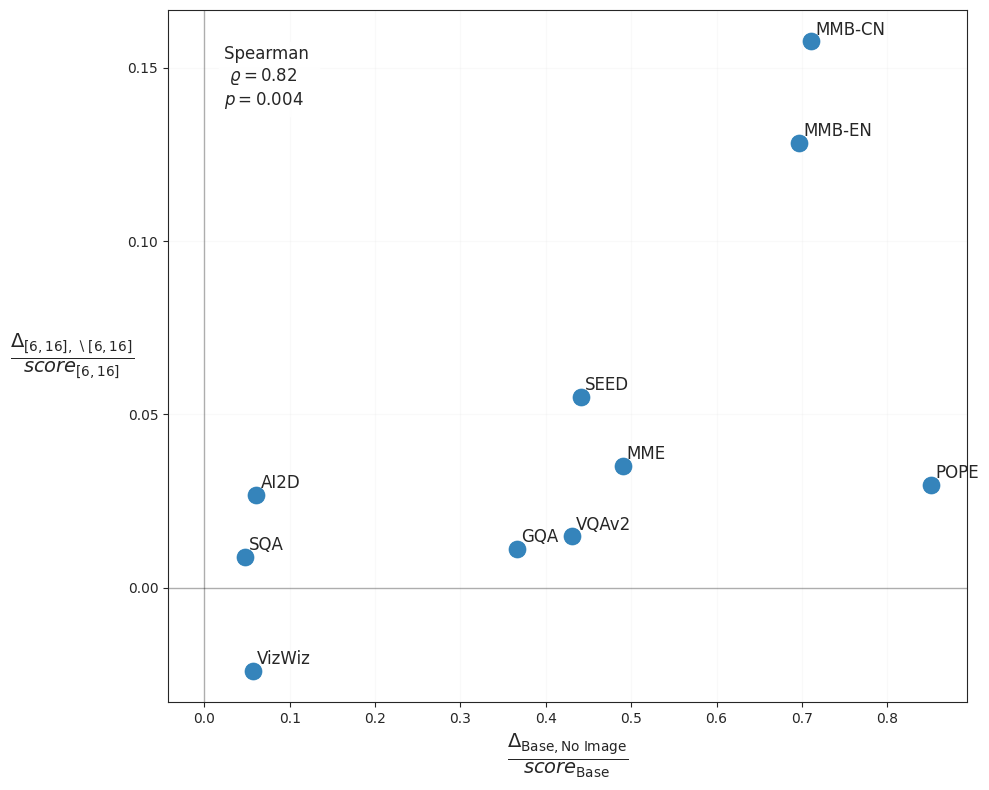

In [39]:

# ==========================================
# New Section: Scatter Plot of Performance Deltas
# ==========================================

def plot_performance_deltas(save_path=None):
    # 1. Reload data to ensure 'llava_7b_noimage' is included if it was recently added
    try:
        global models_to_plot, model_scores
        # Update list of models
        models_to_plot = sorted([
            d for d in os.listdir(EVALS_ROOT) 
            if os.path.isdir(EVALS_ROOT / d) 
            and d != 'llava-1.5-7b' 
            and not d.startswith('.')
        ])
        # Reload scores
        model_scores = load_model_scores()
        print(f"Data reloaded. Available models: {len(models_to_plot)}")
    except NameError:
        print("Error: Helper functions not defined. Run setup cells first.")
        return

    # 2. Define models for comparison
    m_base = 'llava_7b'
    m_noimage = 'llava_7b_noimage'
    m_part1 = 'llava_7b_6_17'
    m_part2 = 'llava_7b_6_17_complementary'

    target_models = [m_base, m_noimage, m_part1, m_part2]
    # Check if critical models exist
    if m_base not in model_scores:
        print(f"Error: Base model {m_base} missing.")
        return
        
    missing = [m for m in target_models if m not in model_scores]
    if missing:
        print(f"Warning: The following models are missing from the data: {missing}")
        # Proceed only if we have pairs for at least some calculation
    
    # 3. Calculate Deltas
    # Delta X: (Base - NoImage) / Base
    # Delta Y: (6_17 - Complementary) / 6_17
    
    x_vals = []
    y_vals = []
    labels = []
    
    print(f"\n{'Benchmark':<15} | {'Norm Delta X':<20} | {'Norm Delta Y':<20}")
    print("-" * 60)

    for bench_key, bench_info in BENCHMARKS_EXT.items():
        if  'ChartQA' in bench_info['abbrev'] or 'COCO' in bench_info['abbrev'] or 'Flickr' in bench_info['abbrev']:
            continue
        # Get scores
        s_base = model_scores.get(m_base, {}).get(bench_key, 0)
        s_noimg = model_scores.get(m_noimage, {}).get(bench_key, 0)
        s_p1 = model_scores.get(m_part1, {}).get(bench_key, 0)
        s_p2 = model_scores.get(m_part2, {}).get(bench_key, 0)
        
        # We need s_base > 0 and s_p1 > 0 for normalization
        if s_base > 1e-6 and s_p1 > 1e-6:
            dx = (s_base - s_noimg) / s_base
            dy = (s_p1 - s_p2) / s_p1
            
            x_vals.append(dx)
            y_vals.append(dy)
            labels.append(bench_info['abbrev'])
            
            print(f"{bench_info['abbrev']:<15} | {dx:+.4f}               | {dy:+.4f}")
        else:
             print(f"{bench_info['abbrev']:<15} | {'SKIPPED (0 baseline)':<20} | -")


    if not x_vals:
        print("No valid data points found for plotting.")
        return

    # Calculate Spearman Correlation
    from scipy import stats
    spearman_corr, p_value = stats.spearmanr(x_vals, y_vals)
    
    # Identify outliers (Rank diff analysis)
    # Calculate ranks
    x_ranks = stats.rankdata(x_vals)
    y_ranks = stats.rankdata(y_vals)
    
    # Calculate rank difference magnitude
    rank_diffs = []
    for i, lab in enumerate(labels):
        diff = abs(x_ranks[i] - y_ranks[i])
        rank_diffs.append((diff, lab, x_vals[i], y_vals[i]))
    
    # Sort by rank diff (descending)
    rank_diffs.sort(key=lambda x: x[0], reverse=True)
    
    print("\n" + "="*60)
    print("INFLUENTIAL POINTS ANALYSIS (Rank Disagreement)")
    print("Points where Image Importance rank differs most from Split Diff rank")
    print("="*60)
    print(f"{'Benchmark':<15} | {'Rank Diff':<10} | {'X':<10} | {'Y':<10}")
    print("-" * 60)
    for diff, lab, vx, vy in rank_diffs[:5]: # Top 5 diffs
         print(f"{lab:<15} | {diff:>9.1f} | {vx:.3f}      | {vy:.3f}")
    print("="*60 + "\n")

    # 4. Plot
    plt.figure(figsize=(10, 8))
    
    # Scatter points - color code by rank diff? 
    # Let's map rank diff to color intensity
    colors = [d[0] for d in rank_diffs] # We need to map back to original order though
    # Re-map colors to original list order
    diff_map = {lab: diff for diff, lab, _, _ in rank_diffs}
    point_colors = [diff_map[l] for l in labels]
    
    scatter = plt.scatter(x_vals, y_vals, s=150, alpha=0.9, linewidth=0.5)
    # plt.colorbar(scatter, label='Rank Agreement (Darker = Better Agreement)')
    
    # Annotate points
    texts = []
    for x, y, lab in zip(x_vals, y_vals, labels):
        # Bold label for top discordant points
        weight = 'normal'
        texts.append(plt.text(x + 0.005, y + 0.002, lab, fontsize=12, weight=weight))
    
    # Try adjust_text
    try:
        from adjustText import adjust_text
        adjust_text(texts, arrowprops=dict(arrowstyle='-', color='gray', alpha=0.5))
    except ImportError:
        print("Note: adjustText not installed, labels may overlap (pip install adjustText)")
        pass 

    # Axes lines
    plt.axhline(0, color='black', linewidth=1, alpha=0.3)
    plt.axvline(0, color='black', linewidth=1, alpha=0.3)
    
    # Trend line (Linear - just for visual guidance)
    if len(x_vals) > 1:
        z = np.polyfit(x_vals, y_vals, 1)
        p = np.poly1d(z)
        x_trend = np.linspace(min(x_vals), max(x_vals), 100)
        # plt.plot(x_trend, p(x_trend), "-", alpha=0.5)

    # Add statistics box
    stats_text = f"Spearman \n $\\varrho = {spearman_corr:.2f}$\n$p = {p_value:.3f}$"
    plt.text(0.07, 0.95, stats_text, transform=plt.gca().transAxes, fontsize=12,
             verticalalignment='top', bbox=dict(boxstyle='square', facecolor='white', alpha=0.9))

    # plt.title(f"Normalized Performance Delta (Spearman r={spearman_corr:.2f}, p={p_value:.3f})", fontsize=14, weight='bold')
    # plt.title("Normalized Performance Delta", fontsize=14, weight='bold')
    plt.xlabel(r"$\frac{\Delta_{\text{Base},\text{No Image}}}{score_{\text{Base}}}$", fontsize=20)
    plt.ylabel(r"$\frac{\Delta_{[6,16],\setminus[6,16]}}{score_{[6,16]}}$", fontsize=20, rotation=0, labelpad=40, va='center')
    
    import matplotlib.ticker as ticker
    plt.gca().xaxis.set_major_locator(ticker.MultipleLocator(0.1))
    plt.gca().yaxis.set_major_locator(ticker.MultipleLocator(0.05))
    
    plt.grid(True, linestyle='-', alpha=0.1)
    # plt.legend()
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches='tight')
        print(f"Plot saved to {save_path}")
    plt.show()

plot_performance_deltas(save_path='performance_deltas.pdf')

In [29]:
# Calculate and print average performance for all loaded models
print("\nAverage Performance Across All Benchmarks:")
print(f"{'Model':<30} | {'Average Normalized Score':<25}")
print("-" * 60)

model_averages = []

if 'model_scores' in globals():
    for model, scores in model_scores.items():
        if scores:
            # Calculate average of normalized scores
            # Note: scores contains 0 for missing benchmarks, so this average penalizes missing data
            avg_score = sum(scores.values()) / len(scores)
            model_averages.append((model, avg_score/0.6168))

    # Sort by average score (descending)
    model_averages.sort(key=lambda x: x[1], reverse=True)

    for model, avg in model_averages:
        print(f"{model:<30} | {avg:.4f}")
else:
    print("Error: 'model_scores' variable not found. Please run the data loading cells first.")


Average Performance Across All Benchmarks:
Model                          | Average Normalized Score 
------------------------------------------------------------
llava_13b                      | 1.0465
llava_13b_6_21                 | 1.0438
llava_7b                       | 1.0094
llava_7b_0_16                  | 1.0081
llava_13b_6_21_complementary   | 1.0067
llava_7b_6_17                  | 1.0034
llava_7b_16spaced              | 0.9985
llava_7b_8spaced               | 0.9772
llava_7b_6_17_complementary    | 0.9581
llava_7b_16_32                 | 0.9097
llava_7b_frozen                | 0.7482
llava_7b_noimage               | 0.5379


In [52]:
import pandas as pd
import numpy as np

# Define models configuration: (Short Name, Full Key, Baseline Key)
# If Short Name is just the suffix for 7b, we'll handle it, otherwise provide full key mapping if needed.
# For 7b models, baseline is llava_7b. For 13b, baseline is llava_13b.

models_config = [
    # 7B Models
    {'label': '6_17', 'key': 'llava_7b_6_17', 'base': 'llava_7b'},
    {'label': '6_17_complementary', 'key': 'llava_7b_6_17_complementary', 'base': 'llava_7b'},
    {'label': '0_16', 'key': 'llava_7b_0_16', 'base': 'llava_7b'},
    {'label': '16_32', 'key': 'llava_7b_16_32', 'base': 'llava_7b'},
    {'label': '8spaced', 'key': 'llava_7b_8spaced', 'base': 'llava_7b'},
    {'label': '16spaced', 'key': 'llava_7b_16spaced', 'base': 'llava_7b'},
    {'label': 'frozen', 'key': 'llava_7b_frozen', 'base': 'llava_7b'},
    
    # 13B Models
    {'label': '13b_6_21', 'key': 'llava_13b_6_21', 'base': 'llava_13b'},
    {'label': '13b_6_21_comp', 'key': 'llava_13b_6_21_complementary', 'base': 'llava_13b'},
]

dataset_names = sorted(list(BENCHMARKS_EXT.keys()))
results_data = []
final_index_labels = []

# Helper to ensure keys exist
def get_full_key(key_in, available_keys):
    if key_in in available_keys:
        return key_in
    return key_in # Fallback or error handling

for config in models_config:
    full_key = config['key']
    base_key = config['base']
    label = config['label']
    
    if base_key not in model_scores:
        print(f"Warning: Baseline {base_key} not found for {label}. Skipping.")
        continue

    if full_key not in model_scores:
        print(f"Warning: Model {full_key} not found. Skipping.")
        continue
        
    row_data = {}
    row_vals = []
    
    for ds in dataset_names:
        val = model_scores[full_key].get(ds, np.nan)
        base_val = model_scores[base_key].get(ds, np.nan)
        
        if not np.isnan(val) and not np.isnan(base_val) and base_val != 0:
            normalized = (val / base_val)*100
            row_data[ds] = normalized
            row_vals.append(normalized)
        else:
            row_data[ds] = np.nan
    
    if row_vals:
        row_data['Mean'] = np.mean(row_vals)
    else:
        row_data['Mean'] = np.nan
        
    results_data.append(row_data)
    final_index_labels.append(label)

if results_data:
    # Create DataFrame
    df_results = pd.DataFrame(results_data, index=final_index_labels)
    
    # Rename rows (index)
    index_mapping = {
        '6_17': r"$[6,16]$",
        '6_17_complementary': r"$\setminus[6,16]$",
        '0_16': r"$[0,16]$",
        '16_32': r"$[16,32]$",
        '8spaced': r"8-spaced",
        '16spaced': r"16-spaced",
        '13b_6_21': r"$[6,21]$",
        '13b_6_21_comp': r"$\setminus[6,21]$",
        'frozen': 'MLP only'
    }
    df_results.rename(index=index_mapping, inplace=True)
    
    # ---------------------------------------------------------
    # Grouping and Ordering Logic
    # ---------------------------------------------------------
    
    # Mapping: Key -> (Group Name, Abbreviation)
    meta_map = {
        # Open-Ended QA (Explicitly these 3)
        'VQAv2':       ('Open-Ended QA', 'VQAv2'),
        'GQA':         ('Open-Ended QA', 'GQA'),
        'VizWiz':      ('Open-Ended QA', 'VizWiz'),
        
        # Multiple Choice QA (The rest of QAs/Benchmarks)
        'ScienceQA':   ('Multiple Choice QA', 'SQA'),
        'AI2D':        ('Multiple Choice QA', 'AI2D'),
        'TextVQA':     ('Multiple Choice QA', 'TextVQA'),
        'MME':         ('Multiple Choice QA', 'MME'),
        'POPE':        ('Multiple Choice QA', 'POPE'),
        'SEEDBench':   ('Multiple Choice QA', 'SEED'),
        'MMBench-EN':  ('Multiple Choice QA', 'MMB-EN'),
        'MMBench-CN':  ('Multiple Choice QA', 'MMB-CN'),
        
        # Captioning
        'COCO':        ('Captioning', 'COCO'),
        'Flickr':      ('Captioning', 'Flickr')
    }
    
    group_priority = {'Open-Ended QA': 1, 'Multiple Choice QA': 2, 'Captioning': 3, 'Summary': 99}

    def get_sort_key(col_name):
        if col_name == 'Mean':
            return (99, 'Mean')
        if col_name in meta_map:
            grp, abbr = meta_map[col_name]
            prio = group_priority.get(grp, 50)
            return (prio, abbr)
        return (50, col_name)

    # Sort columns
    current_cols = df_results.columns.tolist()
    sorted_cols = sorted(current_cols, key=get_sort_key)
    df_results = df_results[sorted_cols]
    
    # Create MultiIndex
    mi_tuples = []
    for c in sorted_cols:
        if c == 'Mean':
            mi_tuples.append(('Summary', 'Mean'))
        elif c in meta_map:
            mi_tuples.append(meta_map[c])
        else:
            # Fallback for anything unmapped
            mi_tuples.append(('Multiple Choice QA', c))
            
    df_results.columns = pd.MultiIndex.from_tuples(mi_tuples)

    # Generate Latex with explicit escaping disabled to preserve math/cmds
    latex_output = df_results.to_latex(
        float_format="{:0.1f}".format, 
        multicolumn=True, 
        multirow=True, 
        multicolumn_format='c', 
        na_rep="-", 
        escape=False
    )
    
    # Manually inject cmidrule lines
    
    lines = latex_output.splitlines()
    groups = df_results.columns.get_level_values(0)
    
    # Calculate cmidrule ranges
    col_offset = 2 
    
    cmid_parts = []
    start_col = 0
    current_grp = groups[0]
    
    for i, grp in enumerate(groups):
        if grp != current_grp:
            # Close previous group
            end_col = i - 1
            if current_grp != 'Summary': 
                 cmid_parts.append(f"\\cmidrule(lr){{{start_col+col_offset}-{end_col+col_offset}}}")
            
            # Start new
            current_grp = grp
            start_col = i
            
    # Close last group
    end_col = len(groups) - 1
    if current_grp != 'Summary':
         cmid_parts.append(f"\\cmidrule(lr){{{start_col+col_offset}-{end_col+col_offset}}}")
         
    cmid_line = " ".join(cmid_parts)
    
    # Insert command and sections
    new_latex = []
    inserted_cmid = False
    
    # Detect the label to start 13B section
    target_13b = index_mapping['13b_6_21']
    inserted_13b_header = False
    
    for line in lines:
        new_latex.append(line)
        
        # Insert cmidrule after Main Header
        if not inserted_cmid and "\\multicolumn" in line and (groups[0] in line or "Multiple Choice QA" in line):
            new_latex.append(cmid_line)
            inserted_cmid = True
        
        # Insert 13B Section - Look ahead logic or insert before?
        # Since we appended line, we check if we need to insert SEPARATOR BEFORE the NEXT line
        # Actually easier to check if current line CONTAINS the start of 13b
        # But we already appended it. Let's fix loop structure to allow insertion before.
    
    # Re-do loop for section insertion
    final_latex = []
    inserted_cmid = False
    
    for line in lines:
        # Check for 13B header insertion position
        if not inserted_13b_header and target_13b in line:
            final_latex.append(r"\midrule")
            final_latex.append(r"\multicolumn{14}{l}{\textit{LLaVA-13B}} \\") # Spanning all cols (approx 14)
            final_latex.append(r"\midrule")
            inserted_13b_header = True
            
        final_latex.append(line)
        
        # Check for cmidrule insertion (header row)
        if not inserted_cmid and "\\multicolumn" in line and (groups[0] in line or "Multiple Choice QA" in line):
            final_latex.append(cmid_line)
            inserted_cmid = True
            
    print("\n".join(final_latex))
else:
    print("No results to display.")

\begin{tabular}{lrrrrrrrrrrrrr}
\toprule
 & \multicolumn{3}{c}{Open-Ended QA} & \multicolumn{7}{c}{Multiple Choice QA} & \multicolumn{2}{c}{Captioning} & Summary \\
\cmidrule(lr){2-4} \cmidrule(lr){5-11} \cmidrule(lr){12-13}
 & GQA & VQAv2 & VizWiz & AI2D & MMB-CN & MMB-EN & MME & POPE & SEED & SQA & COCO & Flickr & Mean \\
\midrule
$[6,16]$ & 98.2 & 99.4 & 103.0 & 99.3 & 97.4 & 99.1 & 98.6 & 100.3 & 99.8 & 98.8 & 99.1 & 98.2 & 99.3 \\
$\setminus[6,16]$ & 97.1 & 97.9 & 105.5 & 96.7 & 82.1 & 86.3 & 95.1 & 97.4 & 94.4 & 97.9 & 98.6 & 97.2 & 95.5 \\
$[0,16]$ & 99.3 & 98.9 & 96.8 & 99.4 & 97.6 & 100.3 & 102.0 & 100.2 & 99.8 & 102.8 & 98.3 & 99.1 & 99.5 \\
$[16,32]$ & 91.1 & 95.3 & 94.6 & 83.0 & 84.2 & 78.4 & 86.4 & 99.0 & 86.5 & 93.6 & 97.6 & 96.9 & 90.6 \\
8-spaced & 96.4 & 96.9 & 103.9 & 95.5 & 91.8 & 89.7 & 98.5 & 98.7 & 95.9 & 99.2 & 97.8 & 96.2 & 96.7 \\
16-spaced & 98.3 & 98.5 & 102.9 & 101.2 & 96.1 & 98.1 & 97.6 & 99.5 & 98.8 & 100.2 & 100.1 & 97.5 & 99.1 \\
MLP only & 73.6 & 84.1 &

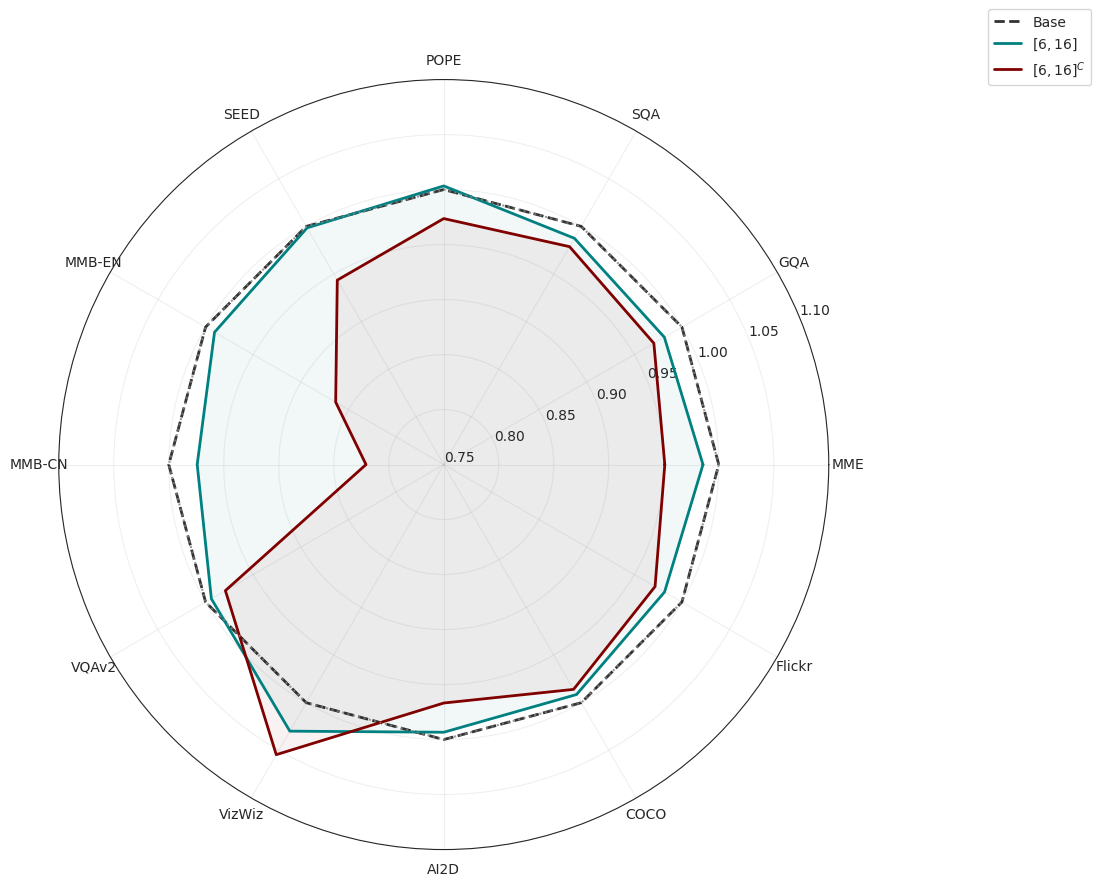

In [42]:
names = {'llava_7b': 'Base', 'llava_7b_6_17': r"$[6,16]$", 'llava_7b_6_17_complementary': r"$[6,16]^C$"}

def plot_custom_radar(scores_data, baseline_name='llava_7b'):
    if not scores_data:
        print("No data to plot")
        return

    # Target models and their colors
    target_models = ['llava_7b', 'llava_7b_6_17', 'llava_7b_6_17_complementary']
    model_colors = {
        'llava_7b': 'black',
        'llava_7b_6_17': 'teal',
        'llava_7b_6_17_complementary': 'maroon'
    }

    if baseline_name not in scores_data:
        print(f"Error: Baseline model '{baseline_name}' not found in results.")
        return

    # Normalize scores relative to baseline
    normalized_data = {}
    baseline_scores = scores_data[baseline_name]
    
    max_val = 0
    
    for model_name in target_models:
        if model_name not in scores_data:
            continue
        benchmarks = scores_data[model_name]
        normalized_data[model_name] = {}
        
        for cat in BENCHMARKS_EXT.keys():
            base_score = baseline_scores.get(cat, 0)
            current_score = benchmarks.get(cat, 0)
            
            if base_score > 1e-6:
                # Calculate ratio: > 1 means better than baseline
                rel_score = current_score / base_score
            else:
                rel_score = 1.0 if current_score > 0 else 0.0
            
            normalized_data[model_name][cat] = rel_score
            max_val = max(max_val, rel_score)

    categories = list(BENCHMARKS_EXT.keys())
    N = len(categories)
    
    # Angles
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]
    
    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(projection='polar'))
    
    for model_name in target_models:
        if model_name not in normalized_data:
            continue
        
        values = []
        for cat in categories:
            values.append(normalized_data[model_name].get(cat, 0))
        values += values[:1]
        
        color = model_colors.get(model_name, 'blue')
        label_text = names.get(model_name, model_name)
        
        if model_name == baseline_name:
            # Baseline style
            ax.plot(angles, values, linewidth=2, linestyle='--', label=label_text, color=color, alpha=0.8)
        else:
            ax.plot(angles, values, linewidth=2, linestyle='solid', label=label_text, color=color)
            ax.fill(angles, values, alpha=0.05, color=color)
    
    # Fix axis
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([BENCHMARKS_EXT[cat]['abbrev'] for cat in categories], size=10)
    
    # Dynamic Y-ticks for normalized plot
    # lower_lim can be adjusted; 0.5 is usually good for normalized plots unless variance is huge
    ax.set_ylim(0.75, max(1.1, max_val + 0.01))
    
    # Add a reference circle at 1.0
    ax.plot(angles, [1.0]*(N+1), color='grey', linestyle=':', linewidth=1.5, alpha=0.8)

    plt.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))
    plt.grid(True, alpha=0.3)
    plt.show()

plot_custom_radar(model_scores, baseline_name='llava_7b')

Combined plot saved to combined_analysis.pdf


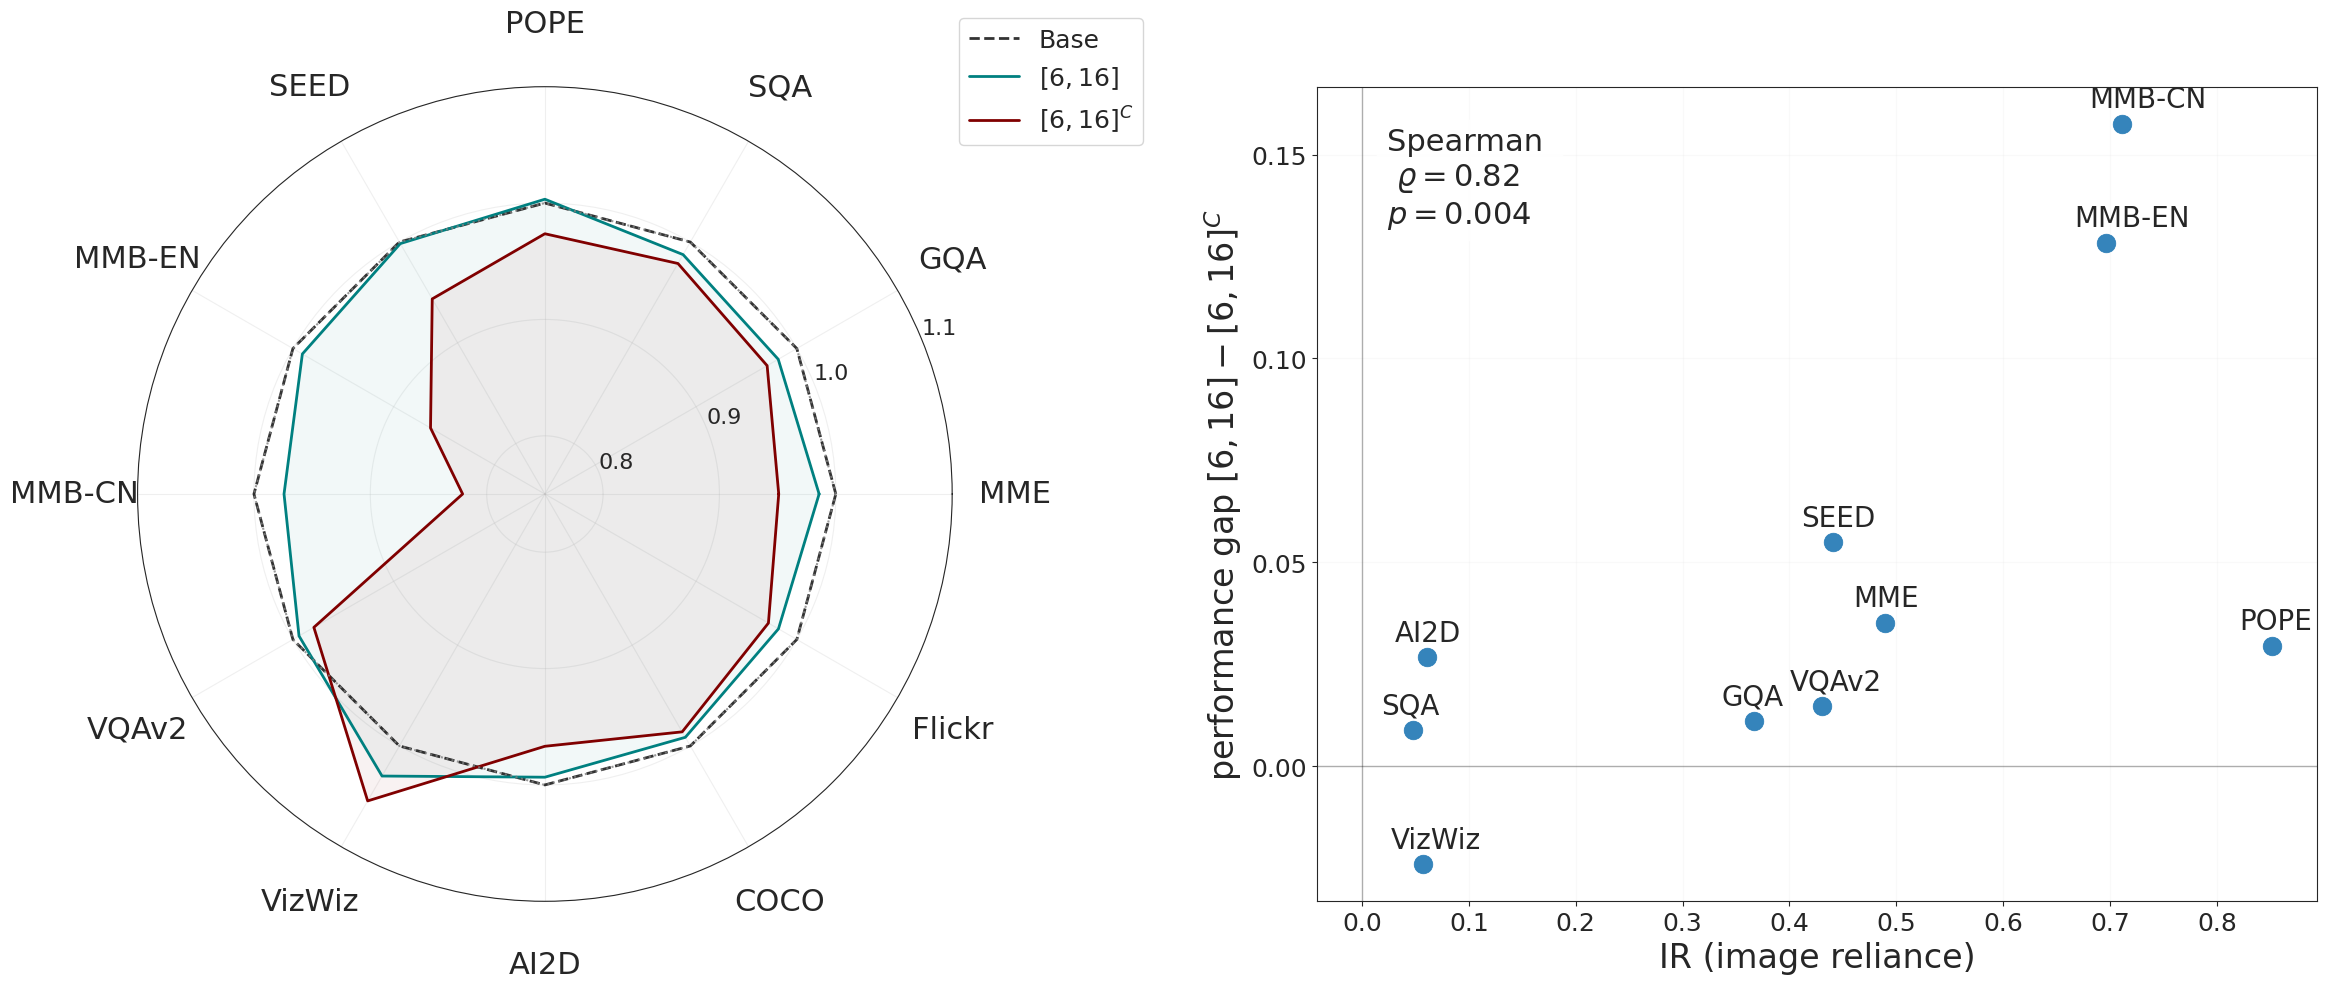

In [50]:
# ==========================================
# Combined Plot: Radar (Left) + Scatter (Right)
# ==========================================

def plot_combined_radar_scatter(save_path=None):
    # Setup Figure with 2 Subplots
    fig = plt.figure(figsize=(24, 10)) # Wide figure
    
    # --- Subplot 1: Radar Chart (Polar) ---
    ax1 = fig.add_subplot(121, projection='polar')
    
    # Radar Logic (Matching plot_custom_radar)
    radar_models = ['llava_7b', 'llava_7b_6_17', 'llava_7b_6_17_complementary']
    radar_colors = {'llava_7b': 'black', 'llava_7b_6_17': 'teal', 'llava_7b_6_17_complementary': 'maroon', 'llava_7b_noimage': 'green'}
    baseline_radar = 'llava_7b'
    
    # Prepare Radar Data
    normalized_data = {}
    baseline_scores = model_scores.get(baseline_radar, {})
    max_val = 0
    categories = list(BENCHMARKS_EXT.keys())
    
    for m in radar_models:
        if m not in model_scores: continue
        normalized_data[m] = {}
        for cat in categories:
            b_score = baseline_scores.get(cat, 0)
            c_score = model_scores[m].get(cat, 0)
            
            if b_score > 1e-6:
                val = c_score / b_score
            else:
                val = 1.0 if c_score > 0 else 0.0
            
            normalized_data[m][cat] = val
            max_val = max(max_val, val)
            
    # Plot Radar
    N = len(categories)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]
    
    for m in radar_models:
        if m not in normalized_data: continue
        values = [normalized_data[m].get(c, 0) for c in categories]
        values += values[:1]
        
        col = radar_colors.get(m, 'blue')
        lbl = names.get(m, m)
        
        if m == baseline_radar:
            ax1.plot(angles, values, linewidth=2, linestyle='--', label=lbl, color=col, alpha=0.8)
        else:
            ax1.plot(angles, values, linewidth=2, linestyle='solid', label=lbl, color=col)
            ax1.fill(angles, values, alpha=0.05, color=col)
            
    ax1.set_xticks(angles[:-1])
    ax1.set_yticks([0.8, 0.9, 1.0, 1.1])
    ax1.set_xticklabels([BENCHMARKS_EXT[c]['abbrev'] for c in categories], size=22)
    ax1.tick_params(axis='x', pad=35)
    ax1.tick_params(axis='y', labelsize=16)
    ax1.set_ylim(0.75, max(1.1, max_val + 0.01))
    ax1.plot(angles, [1.0]*(N+1), color='grey', linestyle=':', linewidth=1.5, alpha=0.8)
    ax1.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1), fontsize=18)
    ax1.grid(True, alpha=0.3)
    
    # --- Subplot 2: Scatter Plot (Rectangular) ---
    ax2 = fig.add_subplot(122)
    
    # Scatter Data Logic (Deltas)
    m_base = 'llava_7b'
    m_noimage = 'llava_7b_noimage'
    m_part1 = 'llava_7b_6_17'
    m_part2 = 'llava_7b_6_17_complementary'
    
    x_vals, y_vals, labels = [], [], []
    
    for bench_key, bench_info in BENCHMARKS_EXT.items():
        if 'ChartQA' in bench_info['abbrev'] or 'COCO' in bench_info['abbrev'] or 'Flickr' in bench_info['abbrev']:
            continue
            
        s_base = model_scores.get(m_base, {}).get(bench_key, 0)
        s_noimg = model_scores.get(m_noimage, {}).get(bench_key, 0)
        s_p1 = model_scores.get(m_part1, {}).get(bench_key, 0)
        s_p2 = model_scores.get(m_part2, {}).get(bench_key, 0)
        
        if s_base > 1e-6 and s_p1 > 1e-6:
            dx = (s_base - s_noimg) / s_base
            dy = (s_p1 - s_p2) / s_p1
            x_vals.append(dx)
            y_vals.append(dy)
            labels.append(bench_info['abbrev'])

    if x_vals:
        # Stats
        from scipy import stats
        spearman_corr, p_value = stats.spearmanr(x_vals, y_vals)
        
        # Plot Scatter
        ax2.scatter(x_vals, y_vals, s=180, alpha=0.9, linewidth=0.5)
        
        # Annotations
        texts = []
        for x, y, lab in zip(x_vals, y_vals, labels):
            texts.append(ax2.text(x - 0.03, y + 0.004, lab, fontsize=20))
            
        # Adjust Text
        try:
            from adjustText import adjust_text
            adjust_text(texts, ax=ax2, arrowprops=dict(arrowstyle='-', color='gray', alpha=0.5))
        except ImportError:
            pass
            
        # Lines & Styling
        ax2.axhline(0, color='black', linewidth=1, alpha=0.3)
        ax2.axvline(0, color='black', linewidth=1, alpha=0.3)
        
        # Stats Box
        stats_text = f"Spearman \n $\\varrho = {spearman_corr:.2f}$\n$p = {p_value:.3f}$"
        ax2.text(0.07, 0.95, stats_text, transform=ax2.transAxes, fontsize=22,
                 verticalalignment='top', bbox=dict(boxstyle='square', facecolor='white', alpha=0.9))
        
        ax2.set_xlabel('IR (image reliance)', fontsize=24)
        ax2.set_ylabel(r'performance gap $[6,16]-[6,16]^C$', fontsize=24, rotation=90, labelpad=20, va='center')
        
        import matplotlib.ticker as ticker
        ax2.xaxis.set_major_locator(ticker.MultipleLocator(0.1))
        ax2.yaxis.set_major_locator(ticker.MultipleLocator(0.05))
        ax2.tick_params(axis='both', which='major', labelsize=18)
        ax2.grid(True, linestyle='-', alpha=0.1)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches='tight')
        print(f"Combined plot saved to {save_path}")
    plt.show()

plot_combined_radar_scatter(save_path='combined_analysis.pdf')

Models found for depth analysis: ['llava_7b_frozen', 'llava_7b', 'llava_7b_0_16', 'llava_7b_16_32', 'llava_7b_0_2', 'llava_7b_0_4', 'llava_7b_0_6', 'llava_7b_0_8', 'llava_7b_0_12', 'llava_7b_0_24', 'llava_7b_8_32', 'llava_7b_30_32', 'llava_7b_28_32', 'llava_7b_26_32', 'llava_7b_24_32', 'llava_7b_20_32']
Plot saved to layer_depth_performance.pdf


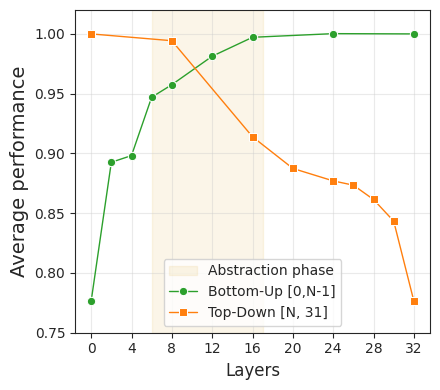

In [27]:

# ==========================================
# New Section: Line Plot for Layer Depth Analysis
# ==========================================

import re
import seaborn as sns
from matplotlib.gridspec import GridSpec

def plot_layer_depth_performance(baseline_model='llava_7b', save_path=None):
    # 1. Reload scores to ensure newly added models are included
    try:
        # Re-identify models in case new folders were added
        global models_to_plot, model_scores # updating globals
        models_to_plot = sorted([
            d for d in os.listdir(EVALS_ROOT) 
            if os.path.isdir(EVALS_ROOT / d) 
            and d != 'llava-1.5-7b' 
            and not d.startswith('.')
        ])
        models_to_plot = ['llava_7b_frozen', 'llava_7b', 'llava_7b_0_16', 'llava_7b_16_32', 'llava_7b_0_2', 'llava_7b_0_4', 'llava_7b_0_6', 'llava_7b_0_8', 'llava_7b_0_12', 'llava_7b_0_24', 'llava_7b_8_32', 'llava_7b_30_32', 'llava_7b_28_32', 'llava_7b_26_32', 'llava_7b_24_32', 'llava_7b_20_32']
        print(f"Models found for depth analysis: {models_to_plot}")
        
        current_scores = load_model_scores() # Use existing function
    except NameError:
        print("Error: 'load_model_scores' not defined. Please run the previous cells first.")
        return

    # 2. Define the mappings for both series
    bottom_up_data = {}
    top_down_data = {}

    # Define explicitly known models or parse dynamically
    for model_name in models_to_plot:
        # Skip if no data
        if model_name not in current_scores or not current_scores[model_name]:
            continue
            
        benchmarks = current_scores[model_name]
        valid_scores = [s for s in benchmarks.values() if s is not None]
        if not valid_scores:
            continue
        avg_score = sum(valid_scores) / len(valid_scores)

        # Classify model
        if model_name == 'llava_7b_frozen':
            # Frozen
            # Bottom-Up (0 to N): N=0 (0 layers trained)
            bottom_up_data[0] = avg_score
            # Top-Down (N to 32): N=32 (0 layers trained, effectively 32 to 32)
            top_down_data[32] = avg_score
            
        elif model_name == 'llava_7b':
            # Full
            # Bottom-Up (0 to N): N=32 (32 layers trained)
            bottom_up_data[32] = avg_score
            # Top-Down (N to 32): N=0 (32 layers trained, 0 to 32)
            top_down_data[0] = avg_score
            
        elif model_name.startswith('llava_7b_'):
            # Parse suffix
            suffix = model_name.replace('llava_7b_', '')
            parts = suffix.split('_')
            
            if len(parts) == 2:
                try:
                    start, end = int(parts[0]), int(parts[1])
                    
                    # Bottom-Up logic: 0_N (layers 0 to N)
                    if start == 0:
                        n_val = end
                        bottom_up_data[n_val] = avg_score
                    
                    # Top-Down logic: N_32 (layers N to 32)
                    elif end == 32:
                        n_val = start
                        top_down_data[n_val] = avg_score
                        
                except ValueError:
                    pass

    # Normalize if baseline exists
    if baseline_model in current_scores:
        valid_b = [s for s in current_scores[baseline_model].values() if s is not None]
        if valid_b:
            baseline_val = sum(valid_b) / len(valid_b)
            
            # Normalize dicts
            for k in bottom_up_data: bottom_up_data[k] /= baseline_val
            for k in top_down_data: top_down_data[k] /= baseline_val
    else:
        print(f"Warning: Baseline {baseline_model} not found. Plotting raw scores.")

    # 3. Sort and Prepare for Plotting
    bu_x = sorted(bottom_up_data.keys())
    bu_y = [bottom_up_data[x] for x in bu_x]
    
    td_x = sorted(top_down_data.keys())
    td_y = [top_down_data[x] for x in td_x]

    # 4. Plot (Style Adapted)
    sns.set_style(
        "whitegrid",
        rc={"axes.edgecolor": ".15", "xtick.bottom": True, "ytick.left": True},
    )
    
    fig = plt.figure(figsize=(4.5, 4))
    gs = GridSpec(1, 1)
    ax = fig.add_subplot(gs[0])
    
    # Abstraction phase highlight
    ax.axvspan(
        6, 17, alpha=0.1, color="#DAA520", zorder=0, label="Abstraction phase"
    )

    # Bottom-Up Line (0 -> 32)
    sns.lineplot(
        x=bu_x,
        y=bu_y,
        marker="o",
        linewidth=1,
        color="#2ca02c",
        label='Bottom-Up [0,N-1]',
        ax=ax
    )
    
    # Top-Down Line (Start N -> 32)
    sns.lineplot(
        x=td_x,
        y=td_y,
        marker="s", 
        linewidth=1,
        color="#ff7f0e",
        label='Top-Down [N, 31]',
        ax=ax
    )

    ax.set_xticks(np.array(list(range(0, 33, 4))))
    ax.set_ylim(0.75, 1.02)
    ax.set_ylabel("Average performance", fontsize=14)
    ax.set_xlabel("Layers", fontsize=12)
    # ax.set_title("Performance vs. Depth", fontsize=15)
    ax.grid(True, alpha=0.4)
    ax.legend(fontsize=10, loc="best")
    
    gs.tight_layout(fig)
    
    if save_path:
        plt.savefig(save_path, bbox_inches='tight')
        print(f"Plot saved to {save_path}")
    plt.show()

plot_layer_depth_performance(baseline_model='llava_7b', save_path='layer_depth_performance.pdf')


In [5]:
# ==========================================
# New Section: Aggregated Group Means Table
# ==========================================

import pandas as pd
import numpy as np

# Group Definitions
group_map = {
    'VQAv2':       'Open-Ended QA',
    'GQA':         'Open-Ended QA',
    'VizWiz':      'Open-Ended QA',
    
    'ScienceQA':   'Multiple Choice QA',
    'AI2D':        'Multiple Choice QA',
    'TextVQA':     'Multiple Choice QA',
    'MME':         'Multiple Choice QA',
    'POPE':        'Multiple Choice QA',
    'SEEDBench':   'Multiple Choice QA',
    'MMBench-EN':  'Multiple Choice QA',
    'MMBench-CN':  'Multiple Choice QA',
    
    'COCO':        'Captioning',
    'Flickr':      'Captioning'
}

# Define models configuration: (Short Label, Full Key, Baseline Key)
model_configs = [
    # 7B Models
    ('6_17', 'llava_7b_6_17', 'llava_7b'),
    ('6_17_complementary', 'llava_7b_6_17_complementary', 'llava_7b'),
    ('0_16', 'llava_7b_0_16', 'llava_7b'),
    ('16_32', 'llava_7b_16_32', 'llava_7b'),
    ('8spaced', 'llava_7b_8spaced', 'llava_7b'),
    ('16spaced', 'llava_7b_16spaced', 'llava_7b'),
    
    # 13B Models
    ('13b_6_21', 'llava_13b_6_21', 'llava_13b'),
    ('13b_6_21_comp', 'llava_13b_6_21_complementary', 'llava_13b')
]

dataset_names = sorted(list(BENCHMARKS_EXT.keys()))
agg_data = []
final_indices = []

for label, full_key, baseline_key in model_configs:
    if baseline_key not in model_scores:
        print(f"Warning: Baseline {baseline_key} missing for {label}.")
        # continue # Proceeding with Check if model exists
        
    if full_key not in model_scores:
        print(f"Propagating Warning: Model {full_key} not found.")
        continue

    # Buckets for scores
    scores_by_group = {'Multiple Choice QA': [], 'Open-Ended QA': [], 'Captioning': []}
    all_valid_scores = []
    
    for ds in dataset_names:
        grp = group_map.get(ds, 'Multiple Choice QA')
        
        val = model_scores[full_key].get(ds, np.nan)
        # Handle missing baseline gracefully if needed, but assuming structure implies existence
        base_val = model_scores.get(baseline_key, {}).get(ds, np.nan)
        
        if not np.isnan(val) and not np.isnan(base_val) and base_val != 0:
            normalized = (val / base_val) * 100
            scores_by_group[grp].append(normalized)
            all_valid_scores.append(normalized)
    
    # Calculate Means
    row = {}
    for grp, vals in scores_by_group.items():
        row[grp] = np.mean(vals) if vals else np.nan
        
    row['Overall Mean'] = np.mean(all_valid_scores) if all_valid_scores else np.nan
    agg_data.append(row)
    final_indices.append(label)

if not agg_data:
    print("No data available for table.")
else:
    # Build DataFrame
    df_agg = pd.DataFrame(agg_data, index=final_indices)
    
    # Rename Rows (LaTeX formatting)
    index_mapping = {
        '6_17': r"$[6,16]$",
        '6_17_complementary': r"$\setminus[6,16]$",
        '0_16': r"$[0,16]$",
        '16_32': r"$[16,32]$",
        '8spaced': r"8-spaced",
        '16spaced': r"16-spaced",
        '13b_6_21': r"$[6,21]$",
        '13b_6_21_comp': r"$\setminus[6,21]$"
    }
    df_agg.rename(index=index_mapping, inplace=True)
    
    # Order Columns
    cols = ['Multiple Choice QA', 'Open-Ended QA', 'Captioning', 'Overall Mean']
    df_agg = df_agg[cols]
    
    # Generate initial LaTeX
    latex_output = df_agg.to_latex(float_format="{:0.1f}".format, escape=False, na_rep="-")
    
    # Post-process for sections
    lines = latex_output.splitlines()
    new_lines = []
    
    # Identify where 13B starts (based on label)
    target_label = index_mapping['13b_6_21']
    
    inserted_header = False
    
    for line in lines:
        # Detect the line containing the first 13B model
        if not inserted_header and target_label in line:
            new_lines.append(r"\midrule")
            new_lines.append(r"\multicolumn{5}{l}{\textit{LLaVA-13B}} \\") # Divider row
            new_lines.append(r"\midrule")
            inserted_header = True
            
        new_lines.append(line)
        
    print("\n".join(new_lines))

\begin{tabular}{lrrrr}
\toprule
 & Multiple Choice QA & Open-Ended QA & Captioning & Overall Mean \\
\midrule
$[6,16]$ & 99.0 & 100.2 & 98.7 & 99.3 \\
$\setminus[6,16]$ & 92.8 & 100.1 & 97.9 & 95.5 \\
$[0,16]$ & 100.3 & 98.3 & 98.7 & 99.5 \\
$[16,32]$ & 87.3 & 93.7 & 97.2 & 90.6 \\
8-spaced & 95.6 & 99.1 & 97.0 & 96.7 \\
16-spaced & 98.8 & 99.9 & 98.8 & 99.1 \\
\midrule
\multicolumn{5}{l}{\textit{LLaVA-13B}} \\
\midrule
$[6,21]$ & 99.8 & 99.3 & 99.0 & 99.6 \\
$\setminus[6,21]$ & 94.5 & 99.3 & 98.0 & 96.3 \\
\bottomrule
\end{tabular}
